# Analyse des données Tania

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)

print("Toutes les bibliothèques fonctionnent !")

NumPy : 2.5.3
Pandas : 3.0.6
Toutes les bibliothèques fonctionnent !


In [6]:
# Importation des données
sans_tel = pd.read_csv("Tania-sans-tel.csv",
                       header=None,
                       names=["Time", "X", "Y", "Z"])

avec_tel = pd.read_csv("Tania-avec-tel.csv",
                       header=None,
                       names=["Time", "X", "Y", "Z"])

# Conversion de la colonne Time en datetime
sans_tel["Time"] = pd.to_datetime(sans_tel["Time"])
avec_tel["Time"] = pd.to_datetime(avec_tel["Time"])

# Vérification
print("Marche sans téléphone :")
print(sans_tel.head())

print("\nMarche avec téléphone :")
print(avec_tel.head())

Marche sans téléphone :
                     Time         X         Y         Z
0 2026-11-15 17:21:15.500  0.203125 -0.093750 -0.968750
1 2026-11-15 17:21:15.510  0.187500 -0.093750 -0.921875
2 2026-11-15 17:21:15.520  0.187500 -0.093750 -0.968750
3 2026-11-15 17:21:15.529  0.187500 -0.078125 -0.968750
4 2026-11-15 17:21:15.539  0.203125 -0.093750 -0.968750

Marche avec téléphone :
                     Time         X         Y         Z
0 2026-11-15 17:26:10.500 -0.812500 -0.312500  0.281250
1 2026-11-15 17:26:10.510 -0.890625 -0.328125  0.281250
2 2026-11-15 17:26:10.520 -1.031250 -0.375000  0.296875
3 2026-11-15 17:26:10.529 -1.156250 -0.375000  0.296875
4 2026-11-15 17:26:10.539 -1.234375 -0.390625  0.281250


In [7]:
def verification(df, nom):
    
    duree = (
        df["Time"].iloc[-1] - df["Time"].iloc[0]
    ).total_seconds()

    frequence = len(df) / duree

    print("\n", nom)
    print("Nombre de mesures :", len(df))
    print("Durée :", round(duree, 2), "secondes")
    print("Fréquence approximative :", round(frequence, 2), "Hz")

    print("\nValeurs manquantes :")
    print(df[["X", "Y", "Z"]].isna().sum())


verification(sans_tel, "Sans téléphone")
verification(avec_tel, "Avec téléphone")


 Sans téléphone
Nombre de mesures : 20640
Durée : 210.15 secondes
Fréquence approximative : 98.22 Hz

Valeurs manquantes :
X    0
Y    0
Z    0
dtype: int64

 Avec téléphone
Nombre de mesures : 20640
Durée : 210.14 secondes
Fréquence approximative : 98.22 Hz

Valeurs manquantes :
X    0
Y    0
Z    0
dtype: int64


In [8]:
def calcul_enmo(df):
    
    df = df.copy()

    # Calcul de la norme de l'accélération
    norme = np.sqrt(
        df["X"]**2 +
        df["Y"]**2 +
        df["Z"]**2
    )

    # Calcul ENMO en mg
    df["ENMO"] = np.maximum(norme - 1, 0) * 1000

    return df


sans_tel = calcul_enmo(sans_tel)
avec_tel = calcul_enmo(avec_tel)

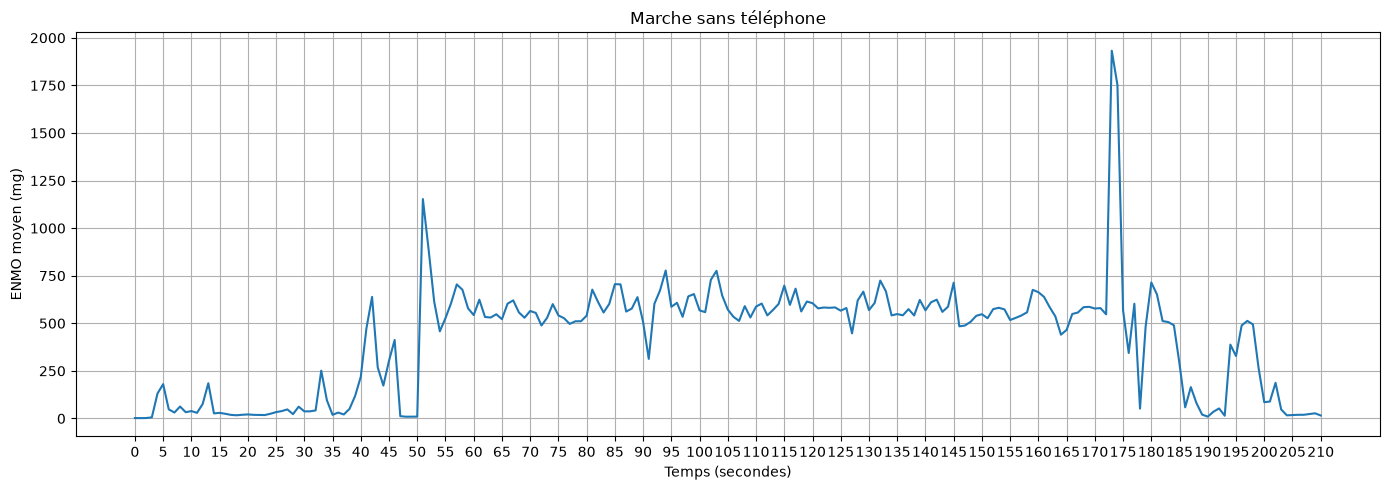

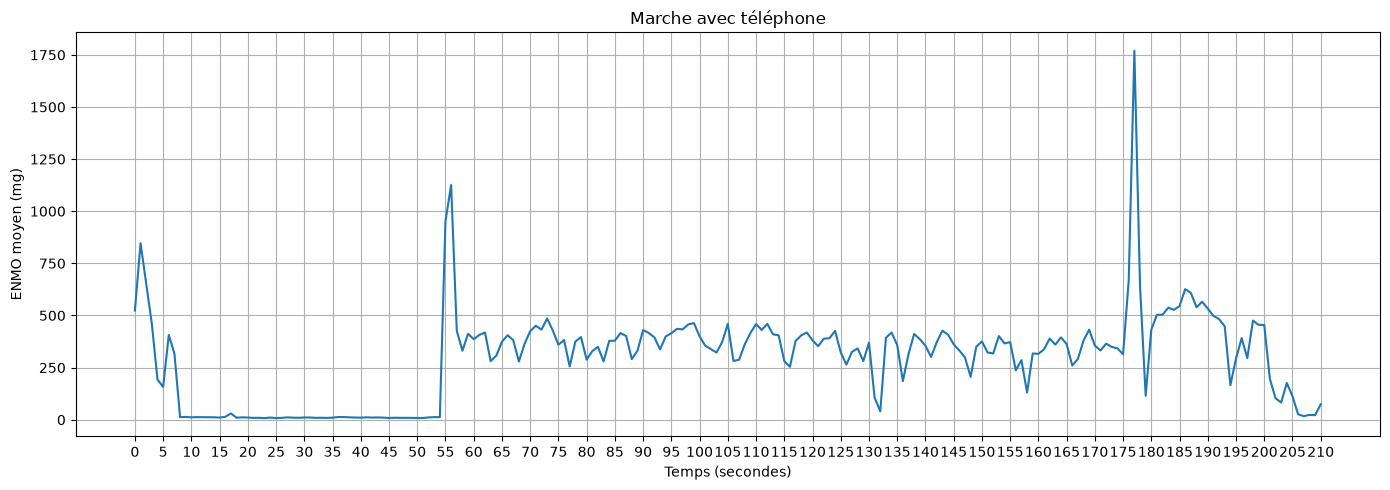

In [9]:
def graphique_enmo(df, titre):
    
    temps = (
        df["Time"] - df["Time"].iloc[0]
    ).dt.total_seconds()

    # ENMO moyen par seconde
    enmo_seconde = df.groupby(
        np.floor(temps).astype(int)
    )["ENMO"].mean()

    plt.figure(figsize=(14, 5))

    plt.plot(
        enmo_seconde.index,
        enmo_seconde.values
    )

    plt.title(titre)
    plt.xlabel("Temps (secondes)")
    plt.ylabel("ENMO moyen (mg)")

    # Graduation toutes les 5 secondes
    plt.xticks(np.arange(0, enmo_seconde.index.max() + 5, 5))

    plt.grid()
    plt.tight_layout()
    plt.show()


# Affichage des deux graphiques
graphique_enmo(sans_tel, "Marche sans téléphone")
graphique_enmo(avec_tel, "Marche avec téléphone")

In [10]:
# A MODIFIER selon tes graphiques

debut_sans_tel = 52
fin_sans_tel = 172

debut_avec_tel = 56
fin_avec_tel = 176

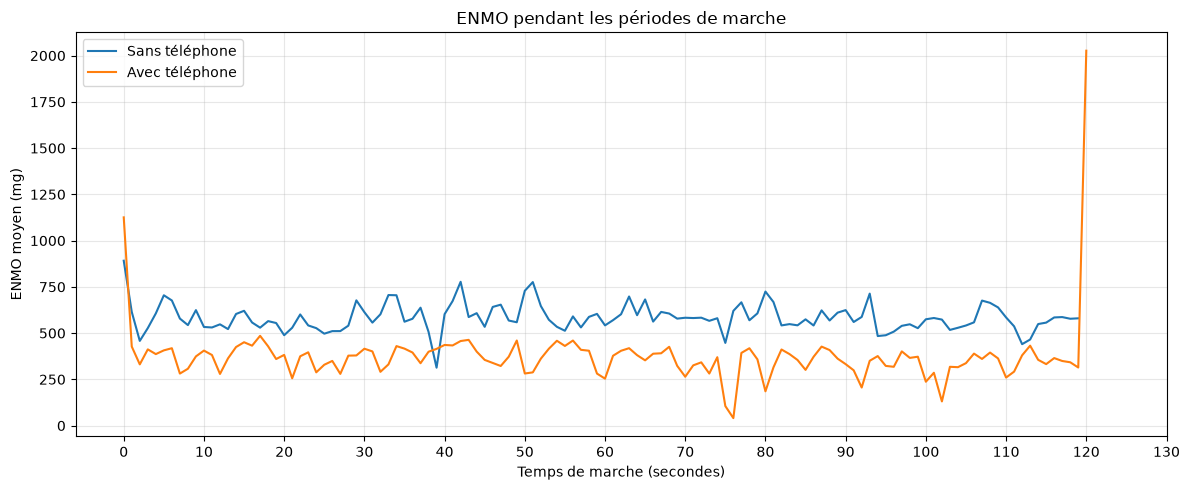

In [11]:
def graphique_periode_marche(df, debut, fin):
    
    # Temps écoulé depuis le début de l'enregistrement
    temps = (
        df["Time"] - df["Time"].iloc[0]
    ).dt.total_seconds()

    # Sélection de la période de marche
    masque = (temps >= debut) & (temps <= fin)

    donnees = df.loc[masque].copy()

    # Temps relatif au début de la marche
    donnees["Temps"] = temps.loc[masque] - debut

    # ENMO moyen par seconde
    donnees["Seconde"] = np.floor(donnees["Temps"]).astype(int)

    enmo = donnees.groupby("Seconde")["ENMO"].mean()

    return enmo


# Extraction des deux périodes de marche
enmo_sans = graphique_periode_marche(
    sans_tel, debut_sans_tel, fin_sans_tel
)

enmo_avec = graphique_periode_marche(
    avec_tel, debut_avec_tel, fin_avec_tel
)


# Graphique comparatif
plt.figure(figsize=(12, 5))

plt.plot(
    enmo_sans.index,
    enmo_sans.values,
    label="Sans téléphone"
)

plt.plot(
    enmo_avec.index,
    enmo_avec.values,
    label="Avec téléphone"
)

plt.xlabel("Temps de marche (secondes)")
plt.ylabel("ENMO moyen (mg)")
plt.title("ENMO pendant les périodes de marche")

plt.xticks(np.arange(0, 131, 10))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
def analyse_condition(df, debut, fin, nom):
    
    # Temps écoulé depuis le début du fichier
    temps = (
        df["Time"] - df["Time"].iloc[0]
    ).dt.total_seconds()

    # Sélection de la période de marche
    masque = (
        (temps >= debut + 10) &
        (temps < fin - 10)
    )

    donnees = df.loc[masque].copy()

    # Temps relatif au début de la période conservée
    donnees["Temps_relatif"] = (
        temps.loc[masque] - (debut + 10)
    )

    # Création des fenêtres de 10 secondes
    donnees["Fenetre"] = (
        np.floor(donnees["Temps_relatif"] / 10)
        .astype(int)
    )

    # Calcul des statistiques par fenêtre
    resultats = donnees.groupby("Fenetre").agg(
        ENMO_moyen=("ENMO", "mean"),
        ENMO_ecart_type=("ENMO", "std"),
        Nombre_mesures=("ENMO", "count")
    )

    # Affichage des résultats
    print("\n", nom)
    print(resultats)

    print("\nENMO moyen global :",
          round(resultats["ENMO_moyen"].mean(), 2), "mg")

    return resultats, donnees

In [13]:
# Analyse marche normale
resultats_sans, donnees_sans = analyse_condition(
    sans_tel,
    debut_sans_tel,
    fin_sans_tel,
    "Marche sans téléphone"
)

# Analyse marche avec téléphone
resultats_avec, donnees_avec = analyse_condition(
    avec_tel,
    debut_avec_tel,
    fin_avec_tel,
    "Marche avec téléphone"
)


 Marche sans téléphone
         ENMO_moyen  ENMO_ecart_type  Nombre_mesures
Fenetre                                             
0        556.186405       726.913127             982
1        542.208333       705.878795             982
2        577.861404       755.778571             982
3        620.175071       752.232300             982
4        608.161292       775.104938             982
5        605.114303       759.370297             983
6        580.406583       725.024189             982
7        594.065664       739.343281             982
8        558.091836       709.641120             983
9        585.230747       737.584916             982

ENMO moyen global : 582.75 mg

 Marche avec téléphone
         ENMO_moyen  ENMO_ecart_type  Nombre_mesures
Fenetre                                             
0        401.127169       570.316055             981
1        341.216658       474.959730             982
2        383.013462       543.791094             982
3        403.682687 

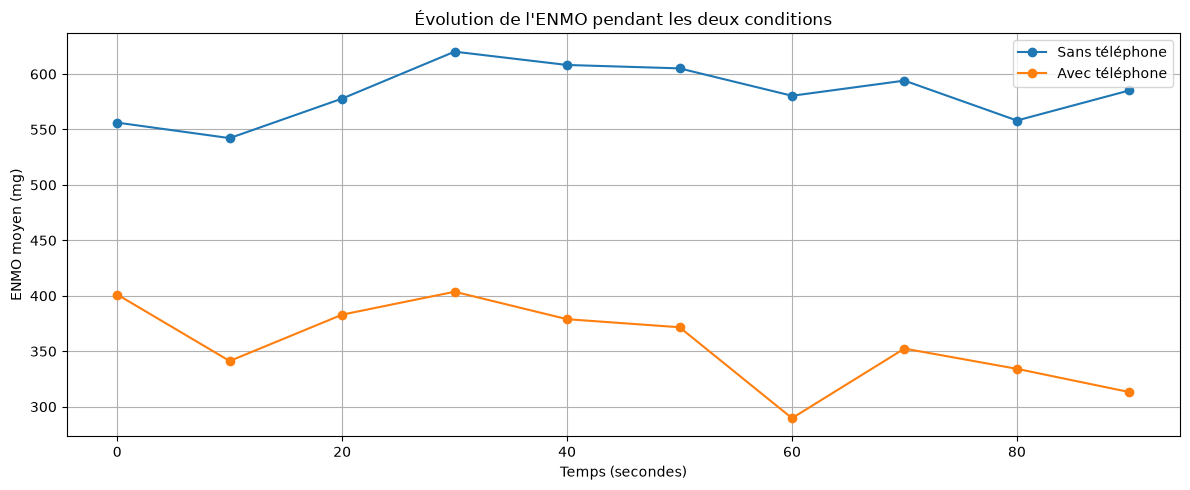

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    resultats_sans["Temps_relatif"] if "Temps_relatif" in resultats_sans.columns else np.arange(len(resultats_sans))*10,
    resultats_sans["ENMO_moyen"],
    marker="o",
    label="Sans téléphone"
)

plt.plot(
    np.arange(len(resultats_avec))*10,
    resultats_avec["ENMO_moyen"],
    marker="o",
    label="Avec téléphone"
)

plt.xlabel("Temps (secondes)")
plt.ylabel("ENMO moyen (mg)")
plt.title("Évolution de l'ENMO pendant les deux conditions")

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [15]:
moyenne_sans = resultats_sans["ENMO_moyen"].mean()
moyenne_avec = resultats_avec["ENMO_moyen"].mean()

print("ENMO moyen sans téléphone :", round(moyenne_sans, 2), "mg")
print("ENMO moyen avec téléphone :", round(moyenne_avec, 2), "mg")

variation = (
    (moyenne_avec - moyenne_sans) / moyenne_sans
) * 100

print("Variation :", round(variation, 2), "%")

# Écart-type entre les fenêtres de 10 secondes

ecart_sans = resultats_sans["ENMO_moyen"].std()
ecart_avec = resultats_avec["ENMO_moyen"].std()

print("Variabilité sans téléphone :", round(ecart_sans, 2), "mg")
print("Variabilité avec téléphone :", round(ecart_avec, 2), "mg")

ENMO moyen sans téléphone : 582.75 mg
ENMO moyen avec téléphone : 356.91 mg
Variation : -38.75 %
Variabilité sans téléphone : 25.09 mg
Variabilité avec téléphone : 37.63 mg


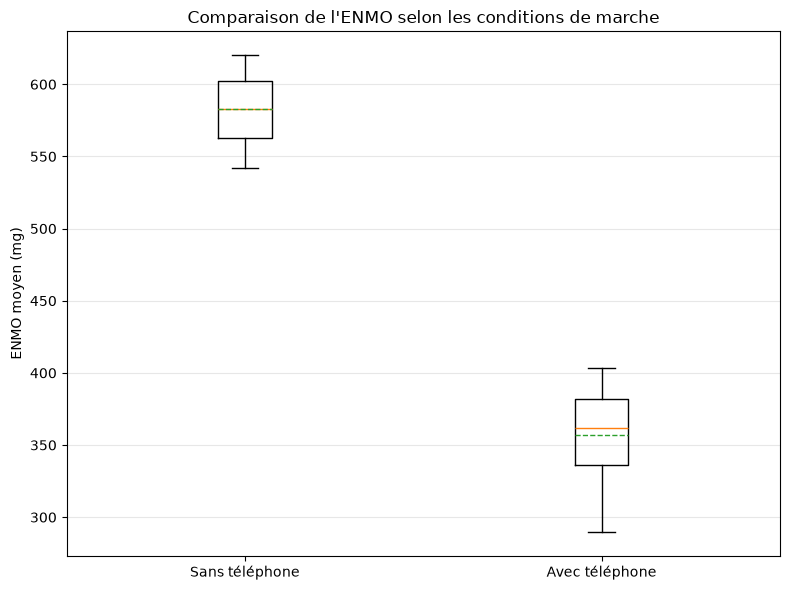

In [16]:
# Préparation des données
donnees_boxplot = [
    resultats_sans["ENMO_moyen"],
    resultats_avec["ENMO_moyen"]]

# Création du diagramme en boîte à moustaches
plt.figure(figsize=(8, 6))

plt.boxplot(
    donnees_boxplot,
    label=["Sans téléphone", "Avec téléphone"],
    showmeans=True,
    meanline=True)

plt.xticks(
    [1, 2],
    ["Sans téléphone", "Avec téléphone"])

plt.ylabel("ENMO moyen (mg)")
plt.title("Comparaison de l'ENMO selon les conditions de marche")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()